# EDA

Default rate by year uses the already-computed train/validation/test numbers.
Everything else (default rate by feature, distributions, correlations) is computed on **train only**.

In [1]:
import json
import os
import sys

# Works whether the kernel's cwd is notebooks/ (normal Jupyter) or the repo
# root (this notebook executed programmatically via nbclient).
if not os.path.isdir('src'):
    os.chdir('..')
sys.path.insert(0, os.getcwd())

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

from src.data.target import labelled_population_query

con = duckdb.connect()
con.execute("SET memory_limit = '8GB'")

TRAIN_SOURCE_QUERY = f"SELECT * FROM ({labelled_population_query()}) WHERE split = 'train' AND target IS NOT NULL"

## Default rate by split

In [2]:
with open('reports/metrics/population_and_target.json') as f:
    pop = json.load(f)
pd.DataFrame(pop['splits']).T

,issue_years,n_fully_paid,n_default,n_excluded_unresolved,n_total_in_population_before_target_filter,n_labelled,default_rate_pct
train,"[2012, 2013]",125611,18281,0,143892,143892,12.7
validation,"[2014, 2014]",140255,22315,0,162570,162570,13.73
test,"[2015, 2015]",240698,42089,147,282934,282787,14.88


## Default rate by grade (train)

In [3]:
df = con.execute(f"SELECT grade, count(*) n, round(100.0*avg(target),2) default_rate_pct FROM ({TRAIN_SOURCE_QUERY}) GROUP BY 1 ORDER BY 1").fetchdf()
df

,grade,n,default_rate_pct
0,A,27810,5.60
1,B,57118,10.60
2,C,34595,15.95
3,D,19593,20.59
4,E,4026,23.03
5,F,711,25.60
6,G,39,20.51


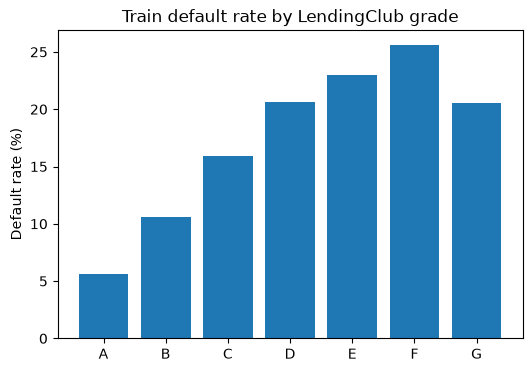

In [4]:
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(df['grade'], df['default_rate_pct'])
ax.set_ylabel('Default rate (%)')
ax.set_title('Train default rate by LendingClub grade')
plt.show()

## Feature distributions (train)

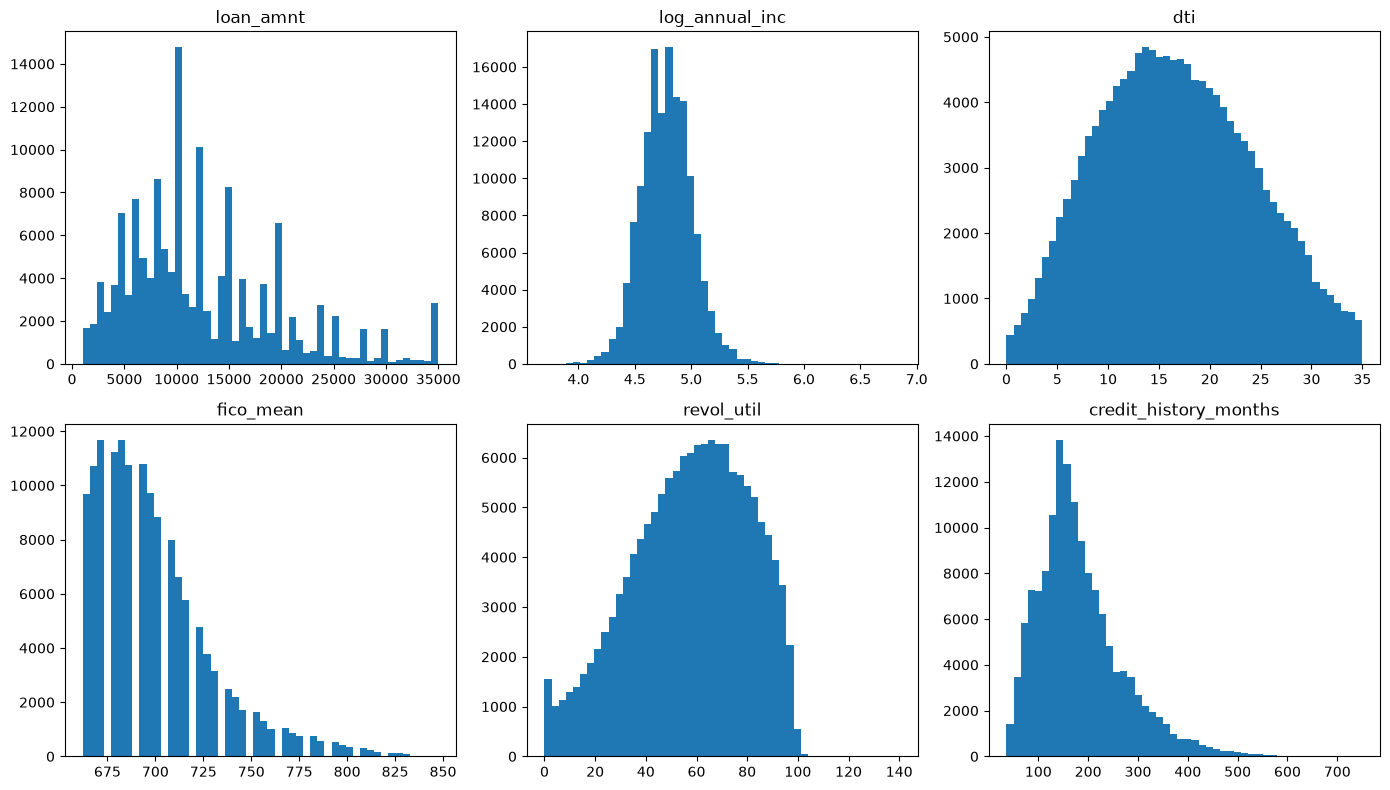

In [5]:
cols = ['loan_amnt', 'log_annual_inc', 'dti', 'fico_mean', 'revol_util', 'credit_history_months']
dist_df = con.execute(f"SELECT {', '.join(cols)} FROM read_parquet('data/processed/train.parquet')").fetchdf()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, cols):
    ax.hist(dist_df[col].dropna(), bins=50)
    ax.set_title(col)
fig.tight_layout()
plt.show()

## Correlation matrix (train)

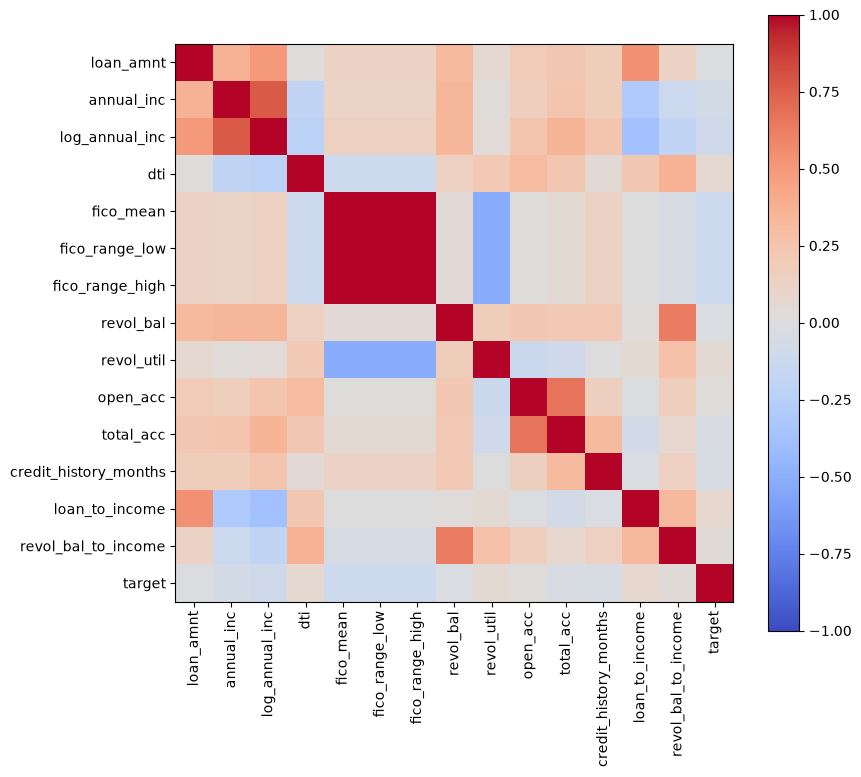

,loan_amnt,annual_inc,log_annual_inc,dti,fico_mean,fico_range_low,fico_range_high,revol_bal,revol_util,open_acc,total_acc,credit_history_months,loan_to_income,revol_bal_to_income,target
loan_amnt,1.00,0.37,0.49,0.01,0.13,0.13,0.13,0.32,0.06,0.19,0.22,0.17,0.55,0.13,-0.02
annual_inc,0.37,1.00,0.77,-0.19,0.11,0.11,0.11,0.34,0.02,0.16,0.24,0.17,-0.29,-0.12,-0.07
log_annual_inc,0.49,0.77,1.00,-0.23,0.14,0.14,0.14,0.34,0.03,0.24,0.35,0.24,-0.37,-0.18,-0.10
dti,0.01,-0.19,-0.23,1.00,-0.11,-0.11,-0.11,0.13,0.21,0.30,0.23,0.04,0.23,0.37,0.07
fico_mean,0.13,0.11,0.14,-0.11,1.00,1.00,1.00,0.04,-0.52,0.01,0.05,0.13,-0.00,-0.05,-0.11
fico_range_low,0.13,0.11,0.14,-0.11,1.00,1.00,1.00,0.04,-0.52,0.01,0.05,0.13,-0.00,-0.05,-0.11
fico_range_high,0.13,0.11,0.14,-0.11,1.00,1.00,1.00,0.04,-0.52,0.01,0.05,0.13,-0.00,-0.05,-0.11
revol_bal,0.32,0.34,0.34,0.13,0.04,0.04,0.04,1.00,0.18,0.22,0.21,0.21,0.01,0.63,-0.03
revol_util,0.06,0.02,0.03,0.21,-0.52,-0.52,-0.52,0.18,1.00,-0.13,-0.09,-0.01,0.05,0.27,0.05
open_acc,0.19,0.16,0.24,0.30,0.01,0.01,0.01,0.22,-0.13,1.00,0.67,0.15,-0.01,0.16,0.00


In [6]:
corr = pd.read_csv('reports/metrics/train_correlation_matrix.csv', index_col=0)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im)
plt.show()
corr.round(2)

**Note:** `loan_amnt`/`funded_amnt` and `fico_range_low`/`fico_range_high`/`fico_mean` are near-perfectly correlated, as expected. The scorecard's correlation/VIF step reduces this redundancy before fitting the model.